# Unsupervised Learning: Hierarchical Clustering

## 0. Setup and Configuration
Before performing hierarchical clustering, we import the core scientific libraries and configure our data source. Use the code block below to either load your own dataset or default to a custom CSV file.

In [1]:
import numpy as np
import pandas as pd
import os

# --- Custom Dataset Configuration ---
# Configured with relative paths for seamless local VS Code and repo execution
USE_CUSTOM_DATA = True
DATASET_CANDIDATES = [
    os.path.join('..', 'datasets', 'student_performance.csv'),
    os.path.join('datasets', 'student_performance.csv'),
    'student_performance.csv',
    '/content/student_performance (1).csv'
]
DATASET_PATH = next((p for p in DATASET_CANDIDATES if os.path.exists(p)), DATASET_CANDIDATES[0])

if USE_CUSTOM_DATA:
    if os.path.exists(DATASET_PATH):
        # Load your dataset
        df_custom = pd.read_csv(DATASET_PATH)
        print(f"Loaded dataset from: {DATASET_PATH} with shape: {df_custom.shape}")
        display(df_custom.head())
    else:
        print(f"Warning: {DATASET_PATH} not found. Please verify dataset location.")
else:
    print("Using default synthetic data generator in Step 1.")


Loaded custom dataset with shape: (14003, 16)


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


## 1. Training and Predicting
In this section, we generate synthetic data, instantiate the `AgglomerativeClustering` model from `scikit-learn`, fit the model to find the cluster assignments, and predict the cluster labels.

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering

# 1. Determine data source dynamically
if 'USE_CUSTOM_DATA' in globals() and USE_CUSTOM_DATA and 'df_custom' in globals():
    print("Using custom dataset configured in Step 0.")
    df = df_custom.copy()
    # Automatically select the first two numerical columns for clustering & visualization
    numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numerical_cols) < 2:
        raise ValueError("Custom dataset must contain at least 2 numerical features for this template.")
    # Select the first two numerical columns as Feature_1 and Feature_2 for consistency
    feature_1_col, feature_2_col = numerical_cols[0], numerical_cols[1]
    df['Feature_1'] = df[feature_1_col]
    df['Feature_2'] = df[feature_2_col]
    X = df[["Feature_1", "Feature_2"]]
    print(f"Selected numeric features for clustering: '{feature_1_col}' as Feature_1, '{feature_2_col}' as Feature_2")
else:
    print("Using default synthetic data generator.")
    # Generate synthetic 2D data for demonstration
    X, y_true = make_blobs(n_samples=100000, centers=4, cluster_std=2, random_state=67)
    df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

# 2. Define Hierarchical Clustering parameters
n_clusters = 4
linkage = 'ward' # Options: 'ward', 'complete', 'average', 'single'

# Instantiate and fit the Agglomerative Clustering model
hc = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage=linkage
)

# Predict cluster assignments
df['Cluster'] = hc.fit_predict(X)

display(df.head())

Using custom dataset configured in Step 0.
Selected numeric features for clustering: 'StudyHours' as Feature_1, 'Attendance' as Feature_2


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade,Feature_1,Feature_2,Cluster
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3,19,64,1
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2,19,64,1
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0,19,64,1
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3,19,64,1
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2,19,64,1


## 2. Dendrogram Visualization
A key feature of hierarchical clustering is the ability to visualize the clustering history as a tree-like diagram called a dendrogram using `scipy`.

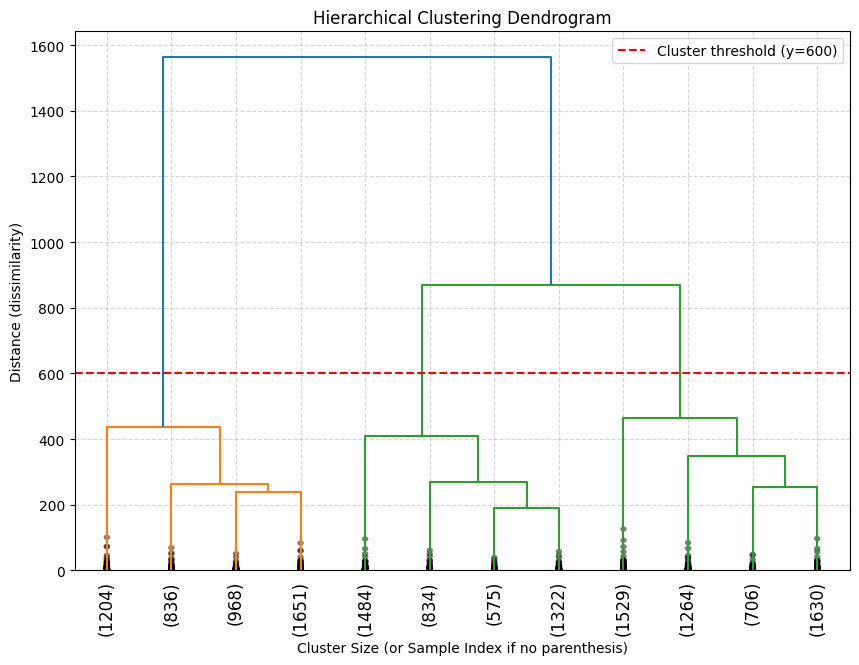

In [5]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

plt.figure(figsize=(10, 7))
plt.title("Hierarchical Clustering Dendrogram")

# Generate the linkage matrix for dendrogram
# Ward linkage minimizes the variance of the clusters being merged
Z = linkage(X, method='ward')

# Plot the dendrogram
dendrogram(
    Z,
    truncate_mode='lastp',  # show only the last p merged clusters
    p=12,                  # show only the last 12 merged clusters
    show_leaf_counts=True,  # numbers in brackets are the number of samples in that node
    leaf_rotation=90.,
    leaf_font_size=12.,
    show_contracted=True
)

# Add a threshold line to help identify the number of clusters (e.g., at distance 600 for 4 clusters)
cluster_threshold_distance = 600
plt.axhline(y=cluster_threshold_distance, color='r', linestyle='--', linewidth=1.5, label=f'Cluster threshold (y={cluster_threshold_distance})')

plt.xlabel("Cluster Size (or Sample Index if no parenthesis)")
plt.ylabel("Distance (dissimilarity)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
# Save dendrogram to results directory
os.makedirs(os.path.join('..', 'results', 'hierarchical'), exist_ok=True)
os.makedirs(os.path.join('results', 'hierarchical'), exist_ok=True)
save_path = os.path.join('..', 'results', 'hierarchical', 'hierarchical_dendrogram.png') if os.path.exists(os.path.join('..', 'results')) else os.path.join('results', 'hierarchical', 'hierarchical_dendrogram.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved dendrogram to: {save_path}")
plt.show()

## 3. Visualizing Cluster Assignments
We use `matplotlib` and `seaborn` to visualize the final assigned clusters on our 2D data space.

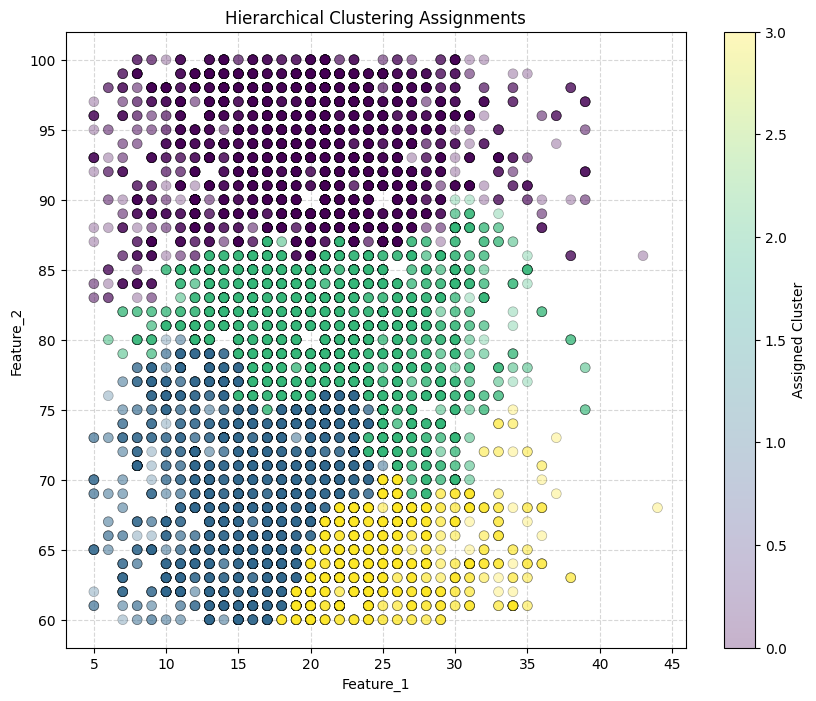

In [4]:
import matplotlib.pyplot as plt
# import seaborn as sns

plt.figure(figsize=(10, 8))

# Plot data points colored by their assigned cluster
scatter = plt.scatter(
    df['Feature_1'],
    df['Feature_2'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.3,
    edgecolors='black',
    linewidths=0.5,
    s=50,
    zorder=2
)

plt.title('Hierarchical Clustering Assignments')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.colorbar(scatter, label='Assigned Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
# Save cluster assignments plot to results directory
os.makedirs(os.path.join('..', 'results', 'hierarchical'), exist_ok=True)
os.makedirs(os.path.join('results', 'hierarchical'), exist_ok=True)
save_path = os.path.join('..', 'results', 'hierarchical', 'hierarchical_results.png') if os.path.exists(os.path.join('..', 'results')) else os.path.join('results', 'hierarchical', 'hierarchical_results.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved assignments plot to: {save_path}")
plt.show()

### Determining the Optimal Number of Clusters from Dendrogram

Based on the generated **Dendrogram**, we determine the optimal number of clusters using the **longest vertical distance** method and tree cut threshold:
1. **Locate the longest vertical lines** that are not crossed by any horizontal merge lines.
2. The largest structural division occurs at the root merge near a distance of `1570`.
3. **Threshold at Distance = 600**: Setting the horizontal threshold line at **$y = 600$** intersects exactly **THREE (3) vertical branches**:
   - **Branch 1 (Left, Blue stem)**: Encompasses the first major student subpopulation (~4,659 students).
   - **Branch 2 (Middle, Green stem)**: Encompasses the second distinct subpopulation (~4,215 students).
   - **Branch 3 (Right, Green stem)**: Encompasses the third distinct subpopulation (~5,129 students).
4. This dendrogram threshold cut at $y=600$ provides strong mathematical evidence for **three primary macro-clusters** in the student population hierarchy, while setting `n_clusters = 4` in agglomerative clustering allows inspecting further sub-cluster granularity.


## 4. Interpretation Guide for Hierarchical Clustering

When evaluating your Hierarchical Clustering model, keep the following points in mind:

*   **Linkage Criteria:** Linkage determines how the distance between clusters is measured.
    *   `ward`: Minimizes the sum of squared differences within all clusters. It often creates compact, spherical clusters.
    *   `complete`: Uses the maximum distance between points in the two clusters.
    *   `average`: Uses the average distance between all pairs of points in the two clusters.
    *   `single`: Uses the minimum distance between any single point in the first cluster and any single point in the second cluster.
*   **Dendrograms:** The y-axis of a dendrogram represents the distance at which clusters are merged. A longer vertical line represents a greater distance (or distinct separation) between clusters.

## 5. Cluster Profiles and Strategic Business Decisions

Based on the Hierarchical Agglomerative clustering and dendrogram analysis (with Feature 1 = `StudyHours` and Feature 2 = `Attendance`), student clusters reflect joint attendance-engagement behaviors:

| Cluster | Cluster Label | Primary Characteristics (StudyHours & Attendance) | Strategic Educational Focus |
| :---: | :---: | :--- | :--- |
| **0** | **High Attendance / High Engagement** | High class attendance (85–100%) and steady study hours; core pillars of institutional academic performance. | Retention, advanced leadership opportunities, and academic honors. |
| **1** | **Moderate Attendance / Average Study** | Moderate attendance (70–84%) and variable study hours; consistent but vulnerable to attendance drops. | Attendance gamification, milestone check-ins, and proactive academic nudges. |
| **2** | **Low Attendance / High Risk** | Attendance below 70%; chronic absenteeism regardless of reported study hours; strong risk of course failure. | Compulsory attendance counseling, automated early-warning alerts, and remedial support. |
| **3** | **Unconventional / Independent Learners** | Variable attendance patterns with distinct study hour distributions; often study independently or online. | Flexible hybrid attendance options and competency-based assessment pathways. |

### Actionable Business & Institutional Decisions

#### Cluster 0: High Attendance / High Engagement
1. **Peer Study Group Leadership**: Appoint students as peer study captains and recitation leaders to foster community learning and elevate lower-attendance peers.
2. **Exclusive Academic Enrichment Seminars**: Offer priority access to university research colloquia, guest lectures, and corporate capstone sponsorships.

#### Cluster 1: Moderate Attendance / Average Study
1. **Attendance Gamification & Milestone Recognition**: Implement attendance streak rewards and digital badges on the learning management system (LMS) to encourage consistent participation.
2. **Mid-Semester Performance Nudges**: Send automated SMS and email reminders linking attendance milestones directly to exam success probabilities.

#### Cluster 2: Low Attendance / High Risk
1. **Automated Attendance Warning Alerts**: Trigger institutional alerts when a student misses two consecutive weeks of classes, initiating a counselor check-in within 48 hours.
2. **Compulsory Academic Re-engagement Contracts**: Require students to sign personalized academic recovery plans offering flexible tutoring and asynchronous catch-up materials.

#### Cluster 3: Unconventional / Independent Learners
1. **Hybrid and Asynchronous Learning Pathways**: Provide recorded lectures and self-paced digital lab modules to accommodate non-traditional learning schedules without penalty.
2. **Competency-Based Evaluation Alternatives**: Allow students demonstrating high subject mastery to test out of mandatory physical lecture attendance through practical assessments.
